# 11. Container With Most Water

## Problem Statement

You are given an integer array `height` of length $n$. There are $n$ vertical lines drawn such that the two endpoints of the $i^{\text{th}}$ line are $(i, 0)$ and $(i, \text{height}[i])$.

Find two lines that together with the x-axis form a container, such that the container contains the most water.

Return the *maximum amount of water a container can store*.

**Notice:** You may not slant the container.

---

### Examples

#### Example 1

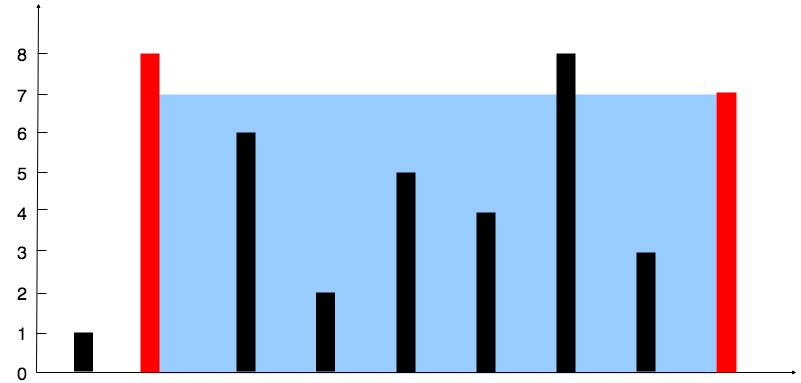


* **Input:** `height = [1,8,6,2,5,4,8,3,7]`
* **Output:** `49`
* **Explanation:** The vertical lines are represented by array `[1,8,6,2,5,4,8,3,7]`. The max area of water the container can contain is formed between lines at index 1 (height 8) and index 8 (height 7), with width $8 - 1 = 7$. Area = $\min(8, 7) \times 7 = 49$.

#### Example 2
* **Input:** `height = [1,1]`
* **Output:** `1`

---

### Constraints
* $n == \text{height.length}$
* $2 \le n \le 10^5$
* $0 \le \text{height}[i] \le 10^4$

---

## Optimal Solution (Two Pointers)

### Intuition & Approach
The area formed between any two vertical lines at indices `left` and `right` is:
$$\text{Area} = \text{width} \times \text{height} = (\text{right} - \text{left}) \times \min(\text{height}[left], \text{height}[right])$$

To find the maximum area efficiently without checking all $\mathcal{O}(n^2)$ pairs:

1. **Initialize Two Pointers:** Start with `left = 0` and `right = n - 1` to maximize the width $(\text{right} - \text{left})$ at the beginning.
2. **Calculate Current Area:** Compute area using the current `left` and `right` boundaries and update `max_area`.
3. **Move the Smaller Pointer:**  
   To potentially find a larger area, we must increase the container height $\min(\text{height}[left], \text{height}[right])$, because moving either pointer inwards *always decreases width*.
   - If `height[left] < height[right]`, increment `left`.
   - Otherwise, decrement `right`.
4. **Repeat** until `left` meets `right`.

In [1]:
class Solution:
    def maxArea(self,height:List[int]) -> int:
        Left,Right = 0,len(height)-1
        max_water = 0
        
        while Left< Right:
            curr_height = min(height[Left],height[Right])
            curr_width = Right-Left
            max_water = max(max_water,curr_height*curr_width)
        
            if height[Left] < height[Right]:
                Left += 1
            else:
                Right -= 1
        return max_water        

In [2]:
sol = Solution()
res= sol.maxArea([1,8,6,2,5,4,8,3,7])
print(res)

49


In [3]:
sol = Solution()
res= sol.maxArea([1,1])
print(res)

1


### Complexity
* **Time Complexity:** $\mathcal{O}(n)$ — Single pass using two pointers.
* **Space Complexity:** $\mathcal{O}(1)$ — Constant extra space used.
